In [58]:
%pip install networkx matplotlib scipy
import networkx as nx
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

Note: you may need to restart the kernel to use updated packages.


<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

### Questão 1
Para a rede do livro "Os miseráveis" (base lesmis), calcule o terceiro e quarto momento do grau. Considere o maior componente conectado.

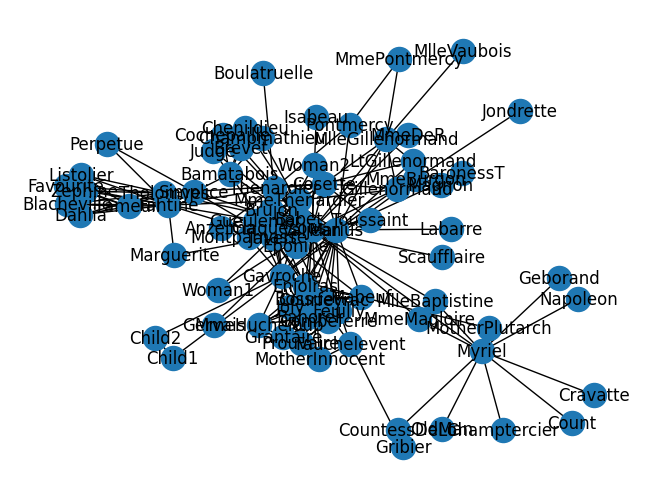

In [59]:
G_lesmis = nx.read_gml('./data/data/lesmis.gml')
nx.draw(G_lesmis, with_labels=True, pos=nx.spring_layout(G_lesmis, k=0.15, iterations=20))

In [60]:
len(sorted(nx.connected_components(G_lesmis)))
# Como só há um componente, vamos prosseguir com o grafo inteiro.

1

In [61]:
def get_nth_moment(G, n):
    degrees = [d for _, d in G.degree()]
    return sum(d**n for d in degrees) / len(G)

print(f"Third Moment: {get_nth_moment(G_lesmis, 3)}")
print(f"Fourth Moment: {get_nth_moment(G_lesmis, 4)}")

Third Moment: 1408.025974025974
Fourth Moment: 33592.72727272727


### Questão 2
Implemente uma rotina para calcular a medida de complexidade. Qual o valor da complexidade para a rede de energia elétrica dos EUA (Base powergrid).

In [62]:
G_powergrid = nx.read_edgelist('./data/data/powergrid.txt', nodetype=int)
len(G_powergrid)

4941

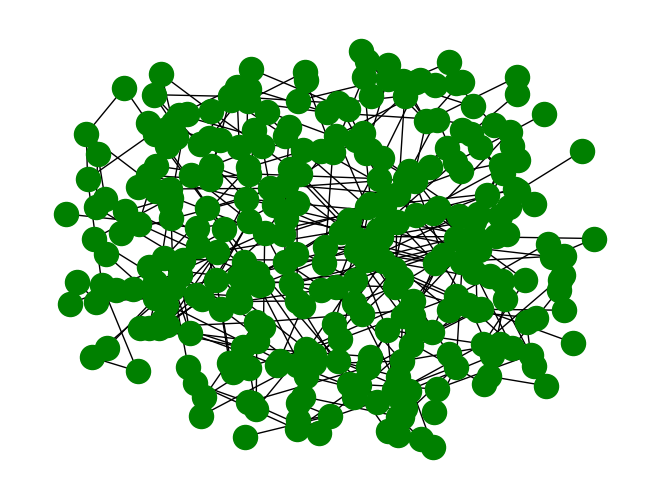

In [63]:
sample_powergrid = G_powergrid.subgraph([i for i in range(300)])
nx.draw(sample_powergrid, node_color='g', pos=nx.spring_layout(sample_powergrid, k=0.15, iterations=20))

In [64]:
def get_complexity(G):
    return get_nth_moment(G, 2) / get_nth_moment(G, 1)

get_complexity(G_powergrid)

3.8712465878070974

### Questão 3
Implemente uma rotina para calcular a entropia de Shannon e calcule essa medida para a base de estradas da Europa (base euroroad).

In [65]:
G_euroroad = nx.read_edgelist('./data/data/euroroad.txt', nodetype=int)
len(G_euroroad)

1174

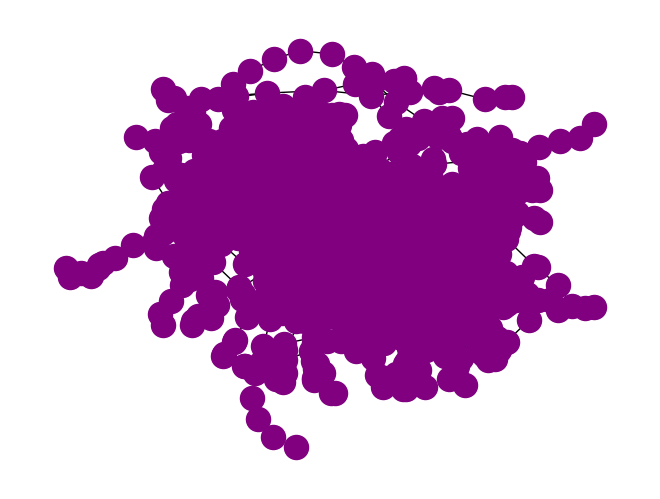

In [66]:
nx.draw(G_euroroad, node_color='purple', pos=nx.spring_layout(G_euroroad, k=0.15, iterations=20))

In [67]:
import collections
import math

def get_entropy(G):
    degrees = [G.degree(n) for n in G.nodes()]
    total_nodes = len(G)
    degree_counts = collections.Counter(degrees)
    degree_prob = [v / total_nodes for v in degree_counts.values()]

    return -sum(p * math.log2(p) for p in degree_prob)

get_entropy(G_euroroad)

2.003310387452775

### Questão 4
Calcule as medidas transitivity e average clustering coefficient para a base de dados de aeroportos do EUA (base usairport.txt).

In [68]:
G_usairport = nx.read_weighted_edgelist('data/data/usairport.txt', nodetype=int)
len(G_usairport)

1574

In [69]:
nx.transitivity(G_usairport), nx.average_clustering(G_usairport)

(0.38414344664491556, 0.504152539209577)

### Questão 5
Calcule o coeficiente de complexidade e a entropia de Shannon para a rede de aeroportos dos EUA (base usairport.txt).

In [70]:
get_complexity(G_usairport), get_entropy(G_usairport)

(112.22224803950043, 4.9859776465392365)